In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import scipy
import scipy.spatial
import scipy.spatial.distance


In [2]:
with open("X.trc", "rb") as f:
    X = torch.load(f)
with open("Y.trc", "rb") as f:
    Y = torch.load(f)
X = X.numpy()
Y = Y.numpy()

/tmp/ipykernel_2111511/979828780.py:2: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  X = torch.load(f)
/tmp/ipykernel_2111511/979828780.py:4: FutureWarning: You are using `t

In [3]:
print(X.shape)
print(Y.shape)

(326132, 18)
(326132, 720)


In [4]:
# samples = np.random.choice(X.shape[0], size=50000, replace=False)
# X_sub = X[samples]
# Y_sub = Y[samples]

X_sub = X
Y_sub = Y

In [5]:
multiplier = np.array([1] * 12 + [1] * 12)

In [6]:
r = 1.75

In [7]:
move_r_mult =  10**(1/18)

In [8]:
def compute_diff(X_data, Y_data):
    x_diff = np.ndarray(X_data.shape[0])
    y_diff = np.ndarray(X_data.shape[0])

    tree = scipy.spatial.KDTree(X_data)
    indices = tree.query_ball_point(X_data, r * move_r_mult, workers=-1)
    for i, index in enumerate(indices):
        x_diff[i] = np.linalg.norm(X_data[index].mean(0) - X_data[i])
        y_diff[i] = np.linalg.norm(Y_data[index].mean(0) - Y_data[i])

    return np.array(x_diff).flatten(), np.array(y_diff).flatten()

In [9]:
X_data, Y_data = X_sub, Y_sub
cum = 1
for i in range(30, 18, -1): # the lower bound is 8
    x_diff, y_diff = compute_diff(X_data, Y_data)
    condition = y_diff < i
    X_data, Y_data = X_data[condition], Y_data[condition]
    cum *= condition.mean()
    print(i, cum, condition.mean())

30 0.9749610587124232 0.9749610587124232
29 0.9640482994615677 0.9888069793625733
28 0.9550396771859246 0.9906554243385166
27 0.9457550930298161 0.9902783262539772
26 0.9354126549985895 0.9890643591481029
25 0.9241135491150823 0.9879207258709534
24 0.911541952338317 0.9863960475541089
23 0.8981332711908062 0.9852901107698725
22 0.8837556572185495 0.9839916697961831
21 0.867792795555174 0.981937471592979
20 0.8507598150442153 0.9803720650848895
19 0.8328345577864179 0.9789302962589203


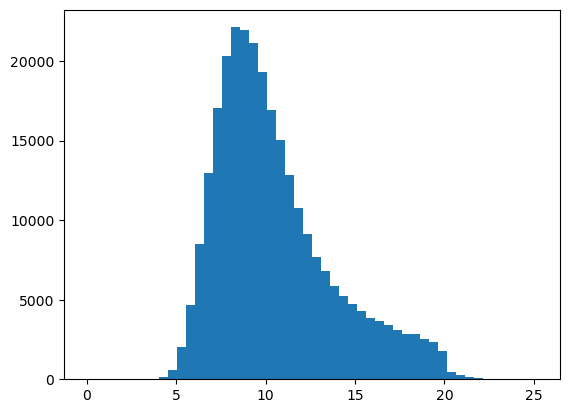

271614


In [10]:
plt.hist(y_diff, bins=50)
plt.show()
print(len(X_data))
with open("X_filtered.trc", "wb") as f:
    torch.save(torch.tensor(X_data), f)
with open("Y_filtered.trc", "wb") as f:
    torch.save(torch.tensor(Y_data), f)

In [13]:
x_diff, y_diff = compute_diff(X, Y)

condition = y_diff < 100
X_data, Y_data = torch.tensor(X[condition]), torch.tensor(Y[condition])
print(len(X_data))
print(condition.mean())

plt.scatter(x_diff[condition], y_diff[condition], s=1)
plt.show()

plt.hist(y_diff[condition], bins=50)
plt.show()


# with open("X_filtered.trc", "wb") as f:
#     torch.save(torch.tensor(X[condition]), f)
# with open("Y_filtered.trc", "wb") as f:
#     torch.save(torch.tensor(Y[condition]), f)


: 

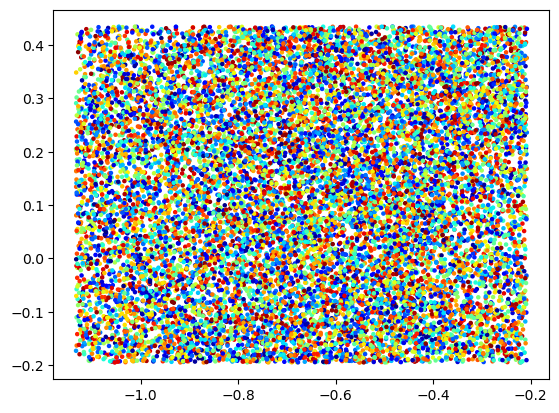

In [22]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X[condition], Y[condition]):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()

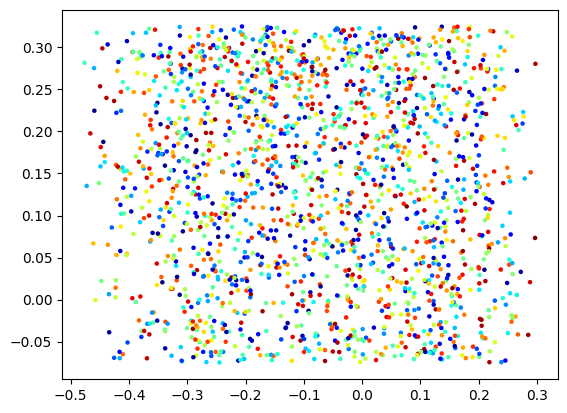

In [28]:
for i in range(0, 1):
    x = []
    y = []
    # z = []
    c = []
    for x_val, y_val in zip(X, Y):
        x.append(x_val[0])
        y.append(x_val[1])
        # z.append(x_val[2])
        c.append(y_val[i])

    fig = plt.figure()
    ax = fig.add_subplot()
    ax.scatter(x, y, c=c, alpha=1, s=5, cmap="jet")
    # plt.savefig(f"test_{i}.png", dpi=1000)
    plt.show()